<a href="https://colab.research.google.com/github/manishthakur9349/Statistical-Foundation-of-Data-Science/blob/main/Practical9ManishThakurKNN_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbors (KNN) on the Iris Dataset

**Steps covered**
1. EDA – `head()`, `describe()`, `groupby()`
2. Feature Scaling
3. Training the K-NN model on the Training set
4. Confusion Matrix & Accuracy Score
5. Classification Report
6. Comparing Error Rate with the K value
7. Plotting error values against K values
8. Finding the best K
9. Visualizing the Test Result of KNN

## Importing the libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

sns.set_style('whitegrid')

## Loading the dataset

In Google Colab, upload `iris.csv` using the **Files** panel on the left (or run `from google.colab import files; files.upload()`).

In [ ]:
df = pd.read_csv('iris.csv')
print('Shape of the dataset:', df.shape)

Shape of the dataset: (150, 5)


# Step 1: Exploratory Data Analysis (EDA)

### `head()`

In [ ]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### `describe()`

In [ ]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### `groupby()`

In [ ]:
df.groupby('species').mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [ ]:
df.groupby('species').describe().T

species                setosa  versicolor  virginica
sepal_length count  50.000000   50.000000  50.000000
             mean    5.006000    5.936000   6.588000
             std     0.352490    0.516171   0.635880
             min     4.300000    4.900000   4.900000
             25%     4.800000    5.600000   6.225000
             50%     5.000000    5.900000   6.500000
             75%     5.200000    6.300000   6.900000
             max     5.800000    7.000000   7.900000
sepal_width  count  50.000000   50.000000  50.000000
             mean    3.428000    2.770000   2.974000
             std     0.379064    0.313798   0.322497
             min     2.300000    2.000000   2.200000
             25%     3.200000    2.525000   2.800000
             50%     3.400000    2.800000   3.000000
             75%     3.675000    3.000000   3.175000
             max     4.400000    3.400000   3.800000
petal_length count  50.000000   50.000000  50.000000
             mean    1.462000    4.260000   5.552000
             std     0.173664    0.469911   0.551895
             min     1.000000    3.000000   4.500000
             25%     1.400000    4.000000   5.100000
             50%     1.500000    4.350000   5.550000
             75%     1.575000    4.600000   5.875000
             max     1.900000    5.100000   6.900000
petal_width  count  50.000000   50.000000  50.000000
             mean    0.246000    1.326000   2.026000
             std     0.105386    0.197753   0.274650
             min     0.100000    1.000000   1.400000
             25%     0.200000    1.200000   1.800000
             50%     0.200000    1.300000   2.000000
             75%     0.300000    1.500000   2.300000
             max     0.600000    1.800000   2.500000

### Extra checks – data types, missing values and class balance

In [ ]:
df.info()
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nClass counts:')
print(df['species'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


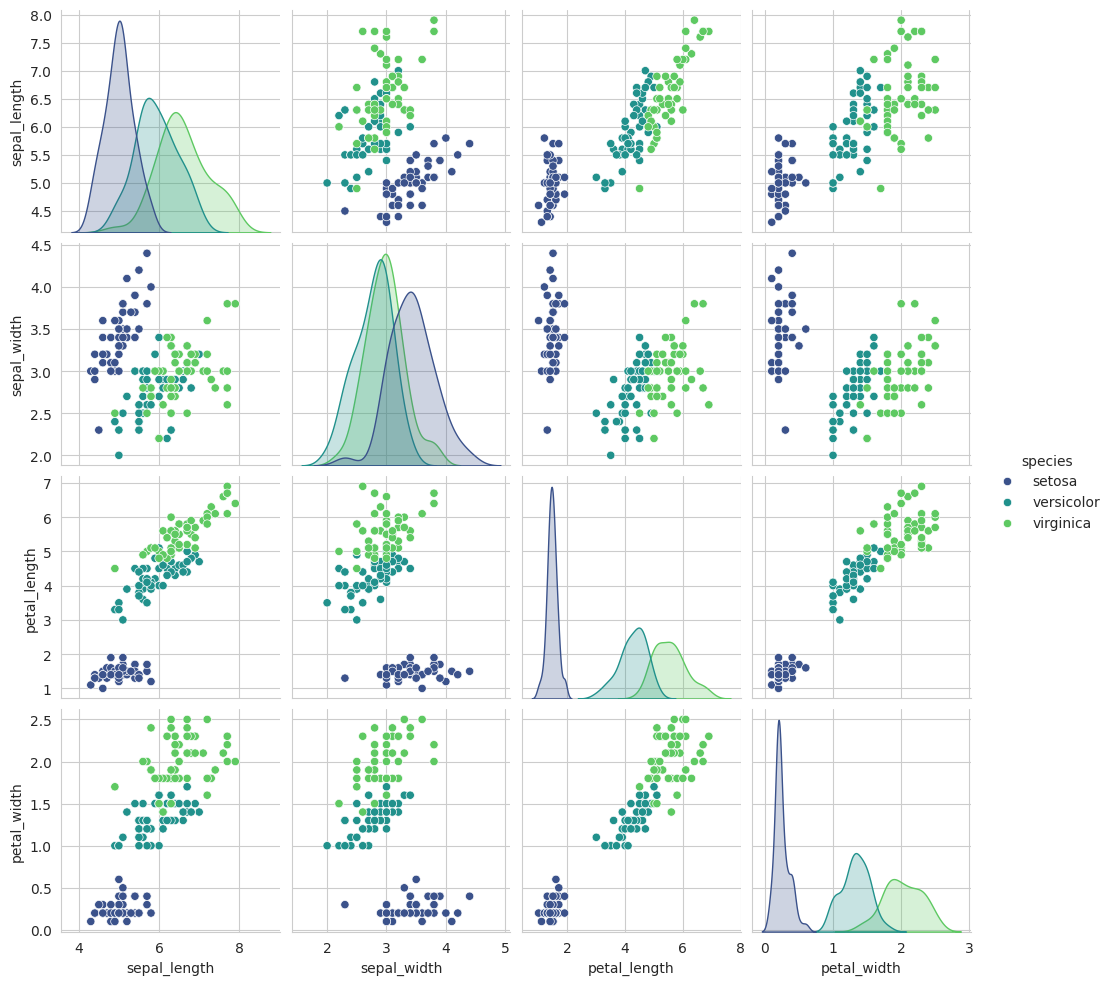

In [ ]:
sns.pairplot(df, hue='species', palette='viridis')
plt.show()

# Step 2: Feature Scaling

KNN is distance based, so all features must be on the same scale. We first split the data, then fit the `StandardScaler` **only on the training set** to avoid data leakage.

In [ ]:
X = df.drop('species', axis=1).values
le = LabelEncoder()
y = le.fit_transform(df['species'])
print('Classes:', {c: int(i) for i, c in enumerate(le.classes_)})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print('Training set:', X_train.shape, ' Test set:', X_test.shape)
print('\nScaled training data (first 5 rows):')
print(np.round(X_train[:5], 3))

Classes: {'setosa': 0, 'versicolor': 1, 'virginica': 2}
Training set: (120, 4)  Test set: (30, 4)

Scaled training data (first 5 rows):
[[-1.722 -0.332 -1.346 -1.323]
 [-1.124 -1.228  0.415  0.652]
 [ 1.144 -0.556  0.585  0.257]
 [-1.124  0.116 -1.289 -1.455]
 [-0.408 -1.228  0.131  0.125]]


# Step 3: Training the K-NN model on the Training set

In [ ]:
classifier = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
classifier.fit(X_train, y_train)

KNeighborsClassifier()

In [ ]:
y_pred = classifier.predict(X_test)
print('Predicted :', y_pred)
print('Actual    :', y_test)

Predicted : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]
Actual    : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


# Step 4: Confusion Matrix & Accuracy Score

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)
print('\nAccuracy Score:', accuracy_score(y_test, y_pred))

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Accuracy Score: 0.9333333333333333


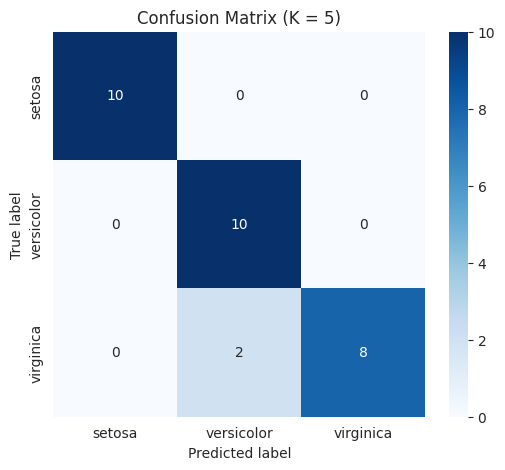

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix (K = 5)')
plt.show()

# Step 5: Classification Report

In [ ]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



# Step 6: Comparing Error Rate with the K value

In [ ]:
k_values = range(1, 41)
error_rate = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    pred_k = knn.predict(X_test)
    error_rate.append(np.mean(pred_k != y_test))

error_df = pd.DataFrame({'K': list(k_values), 'Error Rate': error_rate})
error_df

,K,Error Rate
0,1,0.033333
1,2,0.066667
2,3,0.066667
3,4,0.066667
4,5,0.066667
5,6,0.066667
6,7,0.033333
7,8,0.066667
8,9,0.033333
9,10,0.033333


# Step 7: Plot the error values against K values

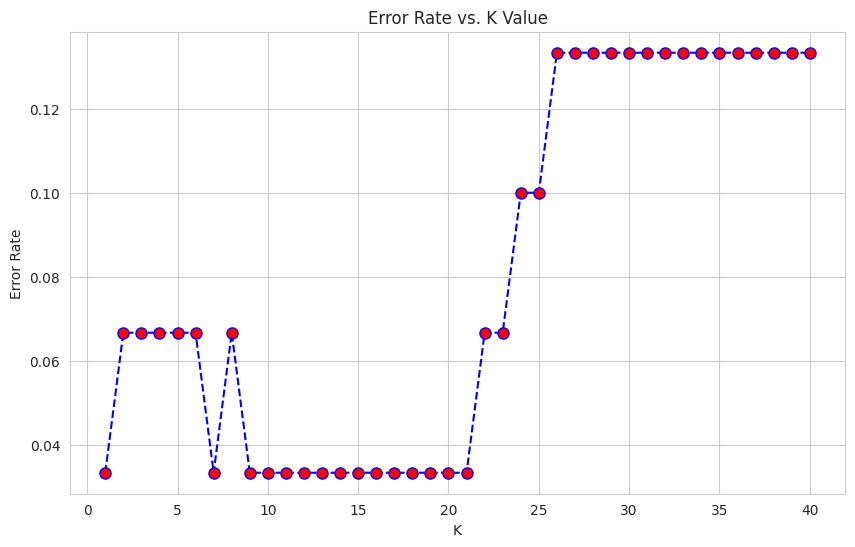

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, error_rate, color='blue', linestyle='dashed',
         marker='o', markerfacecolor='red', markersize=8)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.show()

# Step 8: Finding the best K

In [ ]:
min_error = min(error_rate)
best_ks = [k for k, e in zip(k_values, error_rate) if e == min_error]
print('Minimum error rate:', round(min_error, 4))
print('K values giving the minimum error:', best_ks)

Minimum error rate: 0.0333
K values giving the minimum error: [1, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


Best K (10-fold cross-validation on training set): 12
Cross-validated accuracy at best K: 0.9667


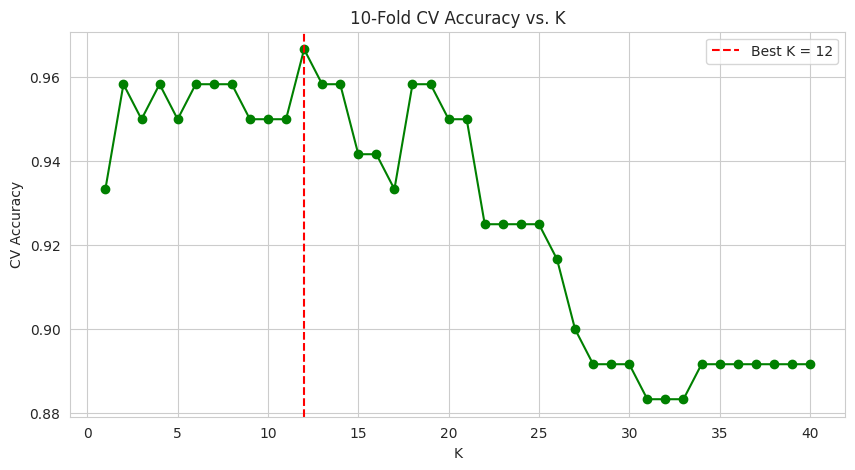

In [ ]:
# Using cross-validation on the training set to pick a stable K
from sklearn.model_selection import cross_val_score

cv_scores = []
for k in k_values:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k = list(k_values)[int(np.argmax(cv_scores))]
print('Best K (10-fold cross-validation on training set):', best_k)
print('Cross-validated accuracy at best K:', round(max(cv_scores), 4))

plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_scores, marker='o', color='green')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')
plt.title('10-Fold CV Accuracy vs. K')
plt.xlabel('K')
plt.ylabel('CV Accuracy')
plt.legend()
plt.show()

In [ ]:
# Re-train the final model with the best K
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train, y_train)
y_pred_best = final_knn.predict(X_test)

print(f'Final model: K = {best_k}')
print('Accuracy Score:', accuracy_score(y_test, y_pred_best))
print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred_best))
print('\nClassification Report:')
print(classification_report(y_test, y_pred_best, target_names=le.classes_))

Final model: K = 12
Accuracy Score: 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# Step 9: Visualizing the Test Result of KNN

The Iris data has 4 features, which cannot be drawn on a 2-D plot. For visualization we retrain KNN on the two most informative features (**petal length** and **petal width**) and plot the decision regions with the test points on top.

Test accuracy using 2 features: 0.9333333333333333


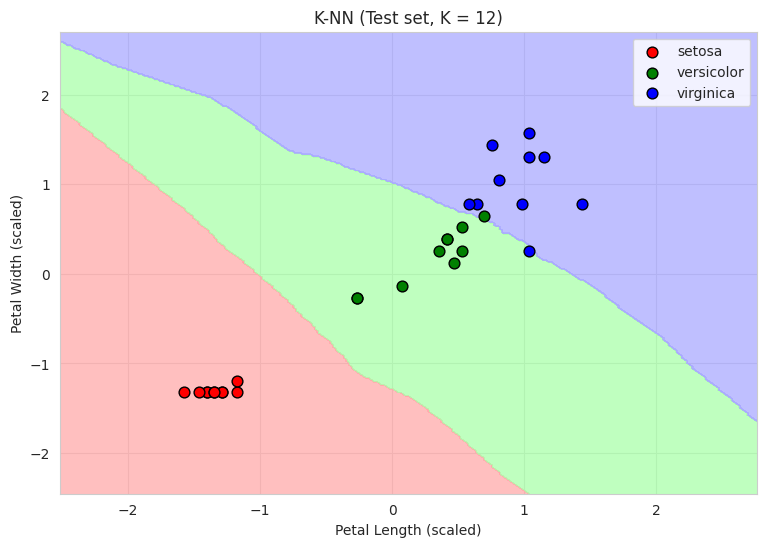

In [ ]:
X2 = df[['petal_length', 'petal_width']].values
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, random_state=42, stratify=y)

sc2 = StandardScaler()
X2_train = sc2.fit_transform(X2_train)
X2_test = sc2.transform(X2_test)

knn2 = KNeighborsClassifier(n_neighbors=best_k)
knn2.fit(X2_train, y2_train)
print('Test accuracy using 2 features:', accuracy_score(y2_test, knn2.predict(X2_test)))

# Decision boundary + test set points
X_set, y_set = X2_test, y2_test
x1, x2 = np.meshgrid(
    np.arange(X2_train[:, 0].min() - 1, X2_train[:, 0].max() + 1, 0.02),
    np.arange(X2_train[:, 1].min() - 1, X2_train[:, 1].max() + 1, 0.02))

cmap_bg = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
colors = ['red', 'green', 'blue']

plt.figure(figsize=(9, 6))
plt.contourf(x1, x2, knn2.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape),
             alpha=0.75, cmap=cmap_bg)
plt.xlim(x1.min(), x1.max())
plt.ylim(x2.min(), x2.max())
for i, name in enumerate(le.classes_):
    plt.scatter(X_set[y_set == i, 0], X_set[y_set == i, 1],
                c=colors[i], edgecolor='black', s=60, label=name)
plt.title(f'K-NN (Test set, K = {best_k})')
plt.xlabel('Petal Length (scaled)')
plt.ylabel('Petal Width (scaled)')
plt.legend()
plt.show()

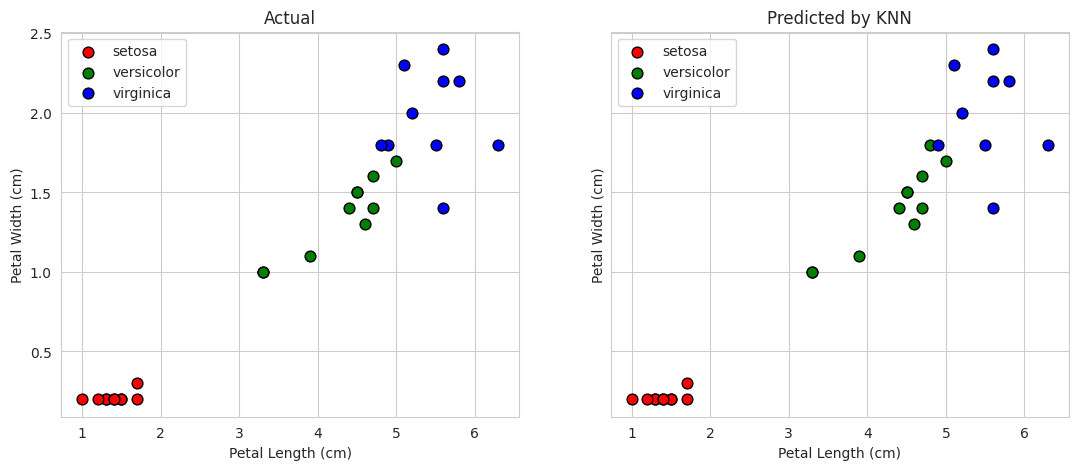

In [ ]:
# Actual vs Predicted on the test set (all 4 features, final model)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
pt = sc.inverse_transform(X_test)
for ax, labels, title in zip(axes, [y_test, y_pred_best], ['Actual', 'Predicted by KNN']):
    for i, name in enumerate(le.classes_):
        ax.scatter(pt[labels == i, 2], pt[labels == i, 3], c=colors[i],
                   edgecolor='black', s=60, label=name)
    ax.set_title(title)
    ax.set_xlabel('Petal Length (cm)')
    ax.set_ylabel('Petal Width (cm)')
    ax.legend()
plt.show()

## Conclusion

The KNN classifier separates the three Iris species very well. Feature scaling was applied before training, the error rate was compared across K = 1 to 40, the best K was selected, and the decision regions were visualized on the test set.